# 03-2. 관측값 추정: 추가 실험

03(관측값 추정 모델)의 3장. 03-1의 후보 외에 다른 고전 머신러닝 기법, MLP 구조, 앙상블 방식, 잔차 공간 보간, 지점 특성 변수를
같은 조건(핵심 변수 12개, 지점 단위 7묶음 교차검증, 지점별 RMSE 평균)으로 비교한다.

03 구성: 03-1 후보 모델·교차검증(1~2장) · **03-2 추가 실험(3장)** · 03-3 검증 지점 평가·시각화·저장(4~6장)

- 입력: 02-2의 지점 변수, 03-1의 교차검증 예측·설정 (`estimation_oof.parquet`, `estimation_cv.json`)
- 출력: 실험 결과 표 (`data/results/estimation_model_comparison.csv`, `estimation_mlp_architectures.csv`,
  `estimation_ensembles.csv`, `estimation_site_correction.csv`)

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parents[1]  # notebooks/<단계 폴더>/ 에서 실행
sys.path.insert(0, str(ROOT))

from src import config

In [ ]:
import json
import time
import warnings

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from cycler import cycler
from matplotlib import font_manager
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

for font in ["NanumGothic", "Malgun Gothic", "AppleGothic"]:
    if any(f.name == font for f in font_manager.fontManager.ttflist):
        plt.rcParams["font.family"] = font
        break
plt.rcParams.update({
    "axes.unicode_minus": False,
    "axes.prop_cycle": cycler(color=["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
                                     "#e87ba4", "#008300", "#4a3aa7", "#e34948"]),
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6,
    "axes.edgecolor": "#c3c2b7", "axes.spines.top": False, "axes.spines.right": False,
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "figure.dpi": 100, "lines.linewidth": 1.5,
})

for d in [config.RESULT_DIR, config.MODEL_DIR, config.FIGURE_DIR]:
    d.mkdir(parents=True, exist_ok=True)

SEED = 42
TARGET = "rst"  # 노면온도

In [ ]:
sf = pd.read_parquet(config.PROCESSED_DIR / "station_features.parquet")
stations = pd.read_parquet(config.PROCESSED_DIR / "stations.parquet").set_index("stn")
FEATURES = json.load(open(config.PROCESSED_DIR / "features.json", encoding="utf-8"))["features"]

# 03-1에서 정한 설정
cv = json.load(open(config.PROCESSED_DIR / "estimation_cv.json", encoding="utf-8"))
CORE, LGB_PARAMS, best_iter = cv["core"], cv["lgb_params"], cv["best_iter"]

def split_holdout(df):
    """검증 지점(config.HOLDOUT_STATIONS)을 학습 데이터에서 분리한다 (03-1의 1장과 같음)."""
    is_holdout = df["stn"].isin(config.HOLDOUT_STATIONS)
    return df[~is_holdout].reset_index(drop=True), df[is_holdout].reset_index(drop=True)


train_all, holdout = split_holdout(sf)
train = train_all.dropna(subset=[TARGET])

# 03-1의 학습 지점 교차검증 예측
oof = pd.read_parquet(config.PROCESSED_DIR / "estimation_oof.parquet")
assert oof["stn"].equals(train_all["stn"]) and oof["time"].equals(train_all["time"])
oof = oof.drop(columns=["stn", "time"])
folds = cv["folds"]

def make_ridge():
    """Ridge(핵심) (03-1의 2장과 같음)."""
    return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), Ridge(alpha=1.0))


print(f"학습 지점 {train_all['stn'].nunique()}곳, 검증 지점 {holdout['stn'].nunique()}곳, 교차검증 예측 {list(oof.columns)}")

## 3. 고전 ML 기법 비교와 추가 실험

2절의 후보 외에 다른 고전 머신러닝 기법, MLP 구조, 앙상블 방식, 지점 특성 변수를 **같은 조건**(핵심 변수 12개, 지점 단위 7묶음 교차검증,
지점별 RMSE 평균)으로 비교한다. 목적은 두 가지이다.

1. LightGBM이 이 문제에 가장 좋은 방법인지 확인한다.
2. 성능을 실제로 제한하는 요인이 모델 형태인지, 자료(지점 수·지점 특성)인지 가린다.

### 3-1. 다른 고전 기법

| 기법 | 설정 | 성격 |
|------|------|------|
| Ridge 상호작용(2차) | 변수 쌍의 곱 66개 추가 + Ridge(α=10) | 계수가 시간대·일사에 따라 변하는 선형 모델 |
| 스플라인 GAM | 변수별 3차 스플라인(매듭 6개) + Ridge | 변수마다 비선형, 변수 간은 가법 |
| kNN | 표준화 변수 공간의 가까운 200개 평균 (학습 15만 행 표본) | 비모수 국소 평균 |
| Random Forest | 150그루, 잎 최소 500행, 그루마다 20% 표본 | 배깅 트리 |
| Extra Trees | 150그루, 잎 최소 500행, 무작위 분할 | 배깅 트리 (분산 더 작음) |
| MLP(64-32) | 은닉층 64-32 (ReLU), L2 1e-3, 조기 종료 (학습 20만 행 표본) | 신경망 |
| LightGBM 선형트리 | 잎마다 선형식을 두는 LightGBM | 부스팅 + 선형 외삽 |
| XGBoost | 깊이 4, 학습률 0.03, 반복 횟수는 LightGBM과 같은 방식으로 선택 | 부스팅 |
| Ridge + 잔차 IDW | Ridge 예측 + 학습 지점의 같은 시각 잔차를 가까운 3곳 IDW로 보간 | 회귀 크리깅의 단순 근사 |

In [12]:
import itertools

import xgboost as xgb
from scipy.optimize import minimize
from sklearn.ensemble import ExtraTreesRegressor, RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import PolynomialFeatures, SplineTransformer


def imputed(*steps):
    return make_pipeline(SimpleImputer(strategy="median"), *steps)


SK_MODELS = {
    "Ridge 상호작용(2차)": lambda: imputed(StandardScaler(), PolynomialFeatures(2, interaction_only=True, include_bias=False),
                                       Ridge(alpha=10.0)),
    "스플라인 GAM": lambda: imputed(SplineTransformer(n_knots=6, extrapolation="linear"), Ridge(alpha=1.0)),
    "kNN(k=200)": lambda: imputed(StandardScaler(), KNeighborsRegressor(n_neighbors=200, n_jobs=-1)),
    "Random Forest": lambda: imputed(RandomForestRegressor(n_estimators=150, min_samples_leaf=500, max_features=0.5,
                                                           max_samples=0.2, n_jobs=-1, random_state=SEED)),
    "Extra Trees": lambda: imputed(ExtraTreesRegressor(n_estimators=150, min_samples_leaf=500, max_features=0.7,
                                                       max_samples=0.2, bootstrap=True, n_jobs=-1, random_state=SEED)),
    "MLP(64-32)": lambda: imputed(StandardScaler(), MLPRegressor(hidden_layer_sizes=(64, 32), alpha=1e-3, batch_size=512,
                                                                 early_stopping=True, max_iter=80, random_state=SEED)),
}
SUBSAMPLE = {"kNN(k=200)": 150_000, "MLP(64-32)": 200_000}
XGB_JOBS = 4  # 이 환경(WSL2)에서는 XGBoost 스레드를 늘릴수록 오히려 느려진다
BOOST_MODELS = {
    "LightGBM 선형트리": ("lgb", dict(LGB_PARAMS["LightGBM(핵심)"], linear_tree=True, linear_lambda=1.0)),
    "XGBoost": ("xgb", dict(n_estimators=600, learning_rate=0.03, max_depth=4, min_child_weight=5000, subsample=0.7,
                            colsample_bytree=0.7, reg_lambda=5.0, tree_method="hist", n_jobs=XGB_JOBS,
                            random_state=SEED, eval_metric="rmse")),
}


def fit_sk(name, df):
    d = df.dropna(subset=[TARGET])
    n = SUBSAMPLE.get(name)
    if n and len(d) > n:
        d = d.sample(n, random_state=SEED)
    return SK_MODELS[name]().fit(d[CORE], d[TARGET])


def boost_fit(kind, params, tr, va=None):
    """va가 있으면 검증 곡선도 돌려준다."""
    tr = tr.dropna(subset=[TARGET])
    if kind == "lgb":
        rec, kw = {}, {}
        if va is not None:
            va = va.dropna(subset=[TARGET])
            kw = dict(eval_set=[(va[CORE], va[TARGET])], eval_metric="rmse", callbacks=[lgb.record_evaluation(rec)])
        m = lgb.LGBMRegressor(**params).fit(tr[CORE], tr[TARGET], **kw)
        return m, (rec["valid_0"]["rmse"] if va is not None else None)
    kw = {}
    if va is not None:
        va = va.dropna(subset=[TARGET])
        kw = dict(eval_set=[(va[CORE], va[TARGET])], verbose=False)
    m = xgb.XGBRegressor(**params).fit(tr[CORE], tr[TARGET], **kw)
    return m, (m.evals_result()["validation_0"]["rmse"] if va is not None else None)


def boost_predict(kind, m, X, n):
    return m.predict(X, num_iteration=n) if kind == "lgb" else m.predict(X, iteration_range=(0, n))


def residual_idw(src_df, src_pred, dst_df, k=3, power=2):
    """src 지점의 같은 시각 잔차(관측 - 예측)를 가까운 k곳 IDW로 dst 지점에 보간한다."""
    res = pd.DataFrame({"stn": src_df["stn"].values, "time": src_df["time"].values,
                        "r": src_df[TARGET].values - src_pred}).pivot(index="time", columns="stn", values="r")
    out = pd.Series(0.0, index=dst_df.index)
    for stn, idx in dst_df.groupby("stn").groups.items():
        dist = pd.Series({s: haversine_km(stations.loc[stn], stations.loc[s]) for s in res.columns}).sort_values()
        R = res[dist.index].reindex(dst_df.loc[idx, "time"].values).to_numpy()
        w = 1 / np.maximum(dist.to_numpy(), 1.0) ** power
        use = ~np.isnan(R) & (np.cumsum(~np.isnan(R), axis=1) <= k)
        num, den = np.where(use, np.nan_to_num(R) * w, 0).sum(1), np.where(use, w, 0).sum(1)
        out[idx] = np.where(den > 0, num / np.where(den > 0, den, 1), 0.0)
    return out.to_numpy()


def haversine_km(a, b):
    la1, lo1, la2, lo2 = map(np.radians, [a["lat"], a["lon"], b["lat"], b["lon"]])
    h = np.sin((la2 - la1) / 2) ** 2 + np.cos(la1) * np.cos(la2) * np.sin((lo2 - lo1) / 2) ** 2
    return 2 * 6371 * np.arcsin(np.sqrt(h))


cmp_time = {}
for name in SK_MODELS:
    t0, pred = time.time(), pd.Series(np.nan, index=train_all.index)
    for val_stns in folds:
        rows = train_all["stn"].isin(val_stns)
        pred[rows] = fit_sk(name, train_all[~rows]).predict(train_all.loc[rows, CORE])
    oof[name], cmp_time[name] = pred, time.time() - t0
    print(f"{name}: {cmp_time[name]:.0f}s")
for name, (kind, params) in BOOST_MODELS.items():
    t0, models_k, curves = time.time(), [], []
    for val_stns in folds:
        rows = train_all["stn"].isin(val_stns)
        m, c = boost_fit(kind, params, train_all[~rows], train_all[rows])
        models_k.append(m)
        curves.append(c)
    best_iter[name] = int(np.argmin(np.mean(curves, axis=0))) + 1
    pred = pd.Series(np.nan, index=train_all.index)
    for m, val_stns in zip(models_k, folds):
        rows = train_all["stn"].isin(val_stns)
        pred[rows] = boost_predict(kind, m, train_all.loc[rows, CORE], best_iter[name])
    oof[name], cmp_time[name] = pred, time.time() - t0
    print(f"{name}: 최적 반복 {best_iter[name]}회, {time.time() - t0:.0f}s")
t0, pred = time.time(), pd.Series(np.nan, index=train_all.index)
for val_stns in folds:
    rows = train_all["stn"].isin(val_stns)
    src = train_all[~rows].dropna(subset=[TARGET])
    m = make_ridge().fit(src[CORE], src[TARGET])
    pred[rows] = m.predict(train_all.loc[rows, CORE]) + residual_idw(src, m.predict(src[CORE]), train_all[rows])
oof["Ridge + 잔차 IDW"], cmp_time["Ridge + 잔차 IDW"] = pred, time.time() - t0

Ridge 상호작용(2차): 4s


스플라인 GAM: 7s


kNN(k=200): 57s


Random Forest: 30s


Extra Trees: 9s


MLP(64-32): 126s


LightGBM 선형트리: 최적 반복 429회, 34s


XGBoost: 최적 반복 528회, 25s


지점별 RMSE를 짝지어 비교한다. "LightGBM보다 나은 지점 수"는 14곳 중 그 방법의 RMSE가 LightGBM(핵심)보다 작은 지점 수,
"차이 ± 표준오차"는 지점별 RMSE 차이(방법 - LightGBM 핵심)의 평균과 표준오차이다. 검증 지점 성능은 참고로만 붙인다.

In [13]:
def per_station_rmse(df, preds, mask=None):
    m = np.ones(len(df), bool) if mask is None else np.asarray(mask)
    e2 = (preds.sub(df[TARGET], axis=0) ** 2)[m]
    return np.sqrt(e2.groupby(df.loc[m, "stn"]).mean())


CMP_METHODS = ["B1 주변 노면온도", "B2 기온+노면편차", "Ridge(핵심)", "Ridge 상호작용(2차)", "스플라인 GAM", "kNN(k=200)",
               "Random Forest", "Extra Trees", "MLP(64-32)", "LightGBM(핵심)", "LightGBM 선형트리", "XGBoost",
               "LightGBM(전체)", "Ridge + 잔차 IDW", "앙상블"]
hr = train_all["time"].dt.hour
st_rmse = per_station_rmse(train_all, oof[CMP_METHODS])
diff = st_rmse.sub(st_rmse["LightGBM(핵심)"], axis=0)
cmp_table = pd.DataFrame({
    "CV RMSE": st_rmse.mean(),
    "밤(19~06시)": per_station_rmse(train_all, oof[CMP_METHODS], (hr >= 19) | (hr <= 6)).mean(),
    "낮(10~15시)": per_station_rmse(train_all, oof[CMP_METHODS], (hr >= 10) & (hr <= 15)).mean(),
    "노면 ≤ 2°C": per_station_rmse(train_all, oof[CMP_METHODS], train_all[TARGET] <= 2).mean(),
    "LightGBM보다 나은 지점 수": (st_rmse.lt(st_rmse["LightGBM(핵심)"], axis=0)).sum(),
    "LightGBM 대비 차이": diff.mean(), "표준오차": diff.std() / np.sqrt(len(diff)),
    "학습 시간(s)": pd.Series(cmp_time),
})

# 검증 지점 (참고): 학습 지점 14곳 전체로 학습
tr_full = train.copy()
ho_cmp = pd.DataFrame(index=holdout.index)
ho_cmp["B1 주변 노면온도"], ho_cmp["B2 기온+노면편차"] = holdout["nbr_rst"], holdout["rst_phys"]
for name in SK_MODELS:
    ho_cmp[name] = fit_sk(name, tr_full).predict(holdout[CORE])
for name, (kind, params) in BOOST_MODELS.items():
    ho_cmp[name] = boost_fit(kind, dict(params, n_estimators=best_iter[name]), tr_full)[0].predict(holdout[CORE])
ridge_full = make_ridge().fit(tr_full[CORE], tr_full[TARGET])
ho_cmp["Ridge(핵심)"] = ridge_full.predict(holdout[CORE])
ho_cmp["Ridge + 잔차 IDW"] = ho_cmp["Ridge(핵심)"] + residual_idw(tr_full, ridge_full.predict(tr_full[CORE]), holdout)
lgb_full = lgb.LGBMRegressor(**dict(LGB_PARAMS["LightGBM(핵심)"], n_estimators=best_iter["LightGBM(핵심)"])).fit(
    tr_full[CORE], tr_full[TARGET])
ho_cmp["LightGBM(핵심)"] = lgb_full.predict(holdout[CORE])
ho_cmp["LightGBM(전체)"] = lgb.LGBMRegressor(**dict(LGB_PARAMS["LightGBM(전체)"], n_estimators=best_iter["LightGBM(전체)"])).fit(
    tr_full[FEATURES], tr_full[TARGET]).predict(holdout[FEATURES])
ho_cmp["앙상블"] = ho_cmp[["LightGBM(핵심)", "Ridge(핵심)", "B1 주변 노면온도"]].mean(axis=1)
cmp_table["검증 지점 RMSE (참고)"] = per_station_rmse(holdout, ho_cmp[CMP_METHODS]).mean()
cmp_table.sort_values("CV RMSE").round(3)

,CV RMSE,밤(19~06시),낮(10~15시),노면 ≤ 2°C,LightGBM보다 나은 지점 수,LightGBM 대비 차이,표준오차,학습 시간(s),검증 지점 RMSE (참고)
앙상블,1.597,1.074,2.363,1.293,9,-0.052,0.022,NaN,0.938
Ridge(핵심),1.612,1.095,2.377,1.285,10,-0.036,0.019,NaN,0.994
LightGBM 선형트리,1.620,1.094,2.391,1.341,12,-0.029,0.010,33.960,1.002
XGBoost,1.638,1.122,2.404,1.366,10,-0.011,0.004,24.840,0.987
B1 주변 노면온도,1.642,1.091,2.459,1.307,7,-0.007,0.057,NaN,0.987
스플라인 GAM,1.647,1.145,2.390,1.372,11,-0.002,0.051,7.043,1.042
Extra Trees,1.647,1.125,2.410,1.362,9,-0.001,0.025,8.960,1.036
LightGBM(핵심),1.649,1.132,2.416,1.378,0,0.000,0.000,NaN,1.003
Random Forest,1.654,1.109,2.455,1.343,8,0.005,0.028,30.462,0.977
Ridge 상호작용(2차),1.664,1.128,2.448,1.379,10,0.015,0.059,4.253,1.068


- **LightGBM이 가장 좋은 방법은 아니다.** 단일 기법 가운데 Ridge(1.612)가 가장 낮고, 14곳 중 10곳에서 LightGBM(핵심)보다 낫다
  (차이 -0.036 ± 0.019°C). LightGBM(핵심, 1.649)은 학습 없이 주변 노면온도를 보간한 B1(1.642)과 같은 수준이다.
- 부스팅(LightGBM, 선형트리, XGBoost), 배깅 트리(RF, Extra Trees), 스플라인 GAM이 모두 1.62~1.65°C에 몰려 있다.
  모델 형태를 바꿔도 결과가 거의 같다는 뜻이다. 차이(최대 0.04°C)는 지점별 차이의 표준오차(0.004~0.08°C)와 비슷하다.
- 더 유연한 모델일수록 나빠진다: kNN 1.684, MLP 1.696, 변수 전체 LightGBM 1.755. 학습 지점 14곳의 고유한 패턴을 외우기 때문이다.
- Ridge + 잔차 IDW(회귀 크리깅의 단순 근사)는 2.223°C로 크게 나빠진다. 이유는 3-4에서 본다.
- 검증 지점(참고)에서도 순위가 뒤섞인다 (RF 0.977, XGBoost·B1 0.987, Ridge 0.994, LightGBM 1.003). 3곳뿐이라 이 차이도 우연 수준이다.
  2절 앙상블(0.938)은 교차검증과 검증 지점 모두에서 가장 낮다.

### 3-2. MLP 구조 실험

신경망은 층을 어떻게 쌓느냐에 따라 결과가 달라질 수 있다. 은닉층의 **너비**(16~256), **깊이**(1~6층), **L2 규제**(1e-5~1),
**활성화 함수**(ReLU, tanh), **목표 변수**(노면온도 자체 / 주변 노면온도 B1과의 차이), **여러 시드 평균**을 바꿔 가며 비교한다.

- 공통: 표준화 입력, Adam, 미니배치 512, 학습 자료의 10%로 조기 종료, 학습 표본 20만 행 (3-1의 MLP와 같음)
- "B1 잔차 학습"은 `rst - nbr_rst`를 학습하고 예측에 `nbr_rst`를 더한다. 신경망이 주변 노면온도에서 출발해 보정량만 배우게 하는 구조이다.
- 7개 묶음을 병렬로 학습한다 (묶음당 BLAS 2스레드).

In [14]:
from joblib import Parallel, delayed
from threadpoolctl import threadpool_limits

MLP_ARCHS = [
    ("1층 16", (16,), {}), ("1층 64", (64,), {}), ("1층 256", (256,), {}),
    ("2층 64-32", (64, 32), {}), ("2층 64-64", (64, 64), {}), ("2층 256-256", (256, 256), {}),
    ("3층 64-64-64", (64, 64, 64), {}), ("3층 128-64-32", (128, 64, 32), {}),
    ("4층 64x4", (64,) * 4, {}), ("4층 256-128-64-32", (256, 128, 64, 32), {}), ("6층 64x6", (64,) * 6, {}),
    ("2층 64-32, L2 1e-5", (64, 32), {"alpha": 1e-5}), ("2층 64-32, L2 0.1", (64, 32), {"alpha": 0.1}),
    ("2층 64-32, L2 1", (64, 32), {"alpha": 1.0}), ("2층 64-32, tanh", (64, 32), {"activation": "tanh"}),
    ("2층 64-32, B1 잔차 학습", (64, 32), {"resid": True}), ("1층 16, B1 잔차 학습", (16,), {"resid": True}),
    ("3층 128-64-32, B1 잔차 학습", (128, 64, 32), {"resid": True}),
    ("2층 64-32, 시드 5개 평균", (64, 32), {"seeds": 5}),
    ("2층 64-32, B1 잔차 + 시드 5개 평균", (64, 32), {"resid": True, "seeds": 5}),
]


def mlp_fold(data, hidden, opt, val_stns, seed):
    """한 묶음의 MLP 학습·예측. data: 학습 지점 자료 (stn, 노면온도, 핵심 변수). 반환: (검증 행 마스크, 예측)."""
    warnings.filterwarnings("ignore", category=UserWarning)  # 병렬 작업 프로세스에도 수렴 경고 숨김
    with threadpool_limits(2):
        va = data["stn"].isin(val_stns).to_numpy()
        tr = data[~va].dropna(subset=[TARGET])
        tr = tr.sample(min(len(tr), 200_000), random_state=SEED)
        y = tr[TARGET] - tr["nbr_rst"] if opt.get("resid") else tr[TARGET]
        ok = y.notna().to_numpy()
        m = imputed(StandardScaler(), MLPRegressor(hidden_layer_sizes=hidden, alpha=opt.get("alpha", 1e-3),
                                                   activation=opt.get("activation", "relu"), batch_size=512,
                                                   early_stopping=True, max_iter=80, random_state=seed))
        m.fit(tr.loc[ok, CORE], y[ok])
        p = m.predict(data.loc[va, CORE])
        return va, p + data.loc[va, "nbr_rst"].to_numpy() if opt.get("resid") else p


mlp_rows, mlp_oof = [], pd.DataFrame(index=train_all.index)
mlp_data = train_all[["stn", TARGET] + CORE]
for name, hidden, opt in MLP_ARCHS:
    t0 = time.time()
    outs = Parallel(n_jobs=7)(delayed(mlp_fold)(mlp_data, hidden, opt, v, SEED + k)
                              for k in range(opt.get("seeds", 1)) for v in folds)
    acc, cnt = np.zeros(len(train_all)), np.zeros(len(train_all))
    for va, p in outs:
        acc[va] += p
        cnt[va] += 1
    mlp_oof[name] = acc / np.maximum(cnt, 1)
    r = per_station_rmse(train_all, mlp_oof[[name]])[name]
    mlp_rows.append({"구조": name, "층 수": len(hidden),
                     "매개변수 수": sum(a * b for a, b in zip((len(CORE),) + hidden, hidden + (1,))) + sum(hidden) + 1,
                     "CV RMSE": r.mean(),
                     "밤(19~06시)": per_station_rmse(train_all, mlp_oof[[name]], (hr >= 19) | (hr <= 6))[name].mean(),
                     "낮(10~15시)": per_station_rmse(train_all, mlp_oof[[name]], (hr >= 10) & (hr <= 15))[name].mean(),
                     "LightGBM보다 나은 지점 수": int((r < st_rmse["LightGBM(핵심)"]).sum()),
                     "학습 시간(s)": time.time() - t0})
    print(f"{name}: RMSE {r.mean():.3f} ({time.time() - t0:.0f}s)")
mlp_table = pd.DataFrame(mlp_rows).set_index("구조")
mlp_table.round(3)

1층 16: RMSE 1.667 (12s)


1층 64: RMSE 1.698 (20s)


1층 256: RMSE 1.692 (63s)


2층 64-32: RMSE 1.696 (34s)


2층 64-64: RMSE 1.708 (41s)


2층 256-256: RMSE 1.764 (266s)


... (11 outputs left out)

3층 128-64-32, B1 잔차 학습: RMSE 1.776 (81s)


2층 64-32, 시드 5개 평균: RMSE 1.681 (173s)


2층 64-32, B1 잔차 + 시드 5개 평균: RMSE 1.688 (178s)


,층 수,매개변수 수,CV RMSE,밤(19~06시),낮(10~15시),LightGBM보다 나은 지점 수,학습 시간(s)
구조,,,,,,,
1층 16,1,225,1.667,1.104,2.478,10,12.158
1층 64,1,897,1.698,1.148,2.502,10,20.153
1층 256,1,3585,1.692,1.111,2.539,8,63.085
2층 64-32,2,2945,1.696,1.102,2.544,8,34.304
2층 64-64,2,5057,1.708,1.130,2.554,8,40.898
2층 256-256,2,69377,1.764,1.188,2.627,5,265.816
3층 64-64-64,3,9217,1.734,1.170,2.592,6,65.194
3층 128-64-32,3,12033,1.741,1.179,2.594,7,78.923
4층 64x4,4,13377,1.774,1.193,2.651,5,91.332


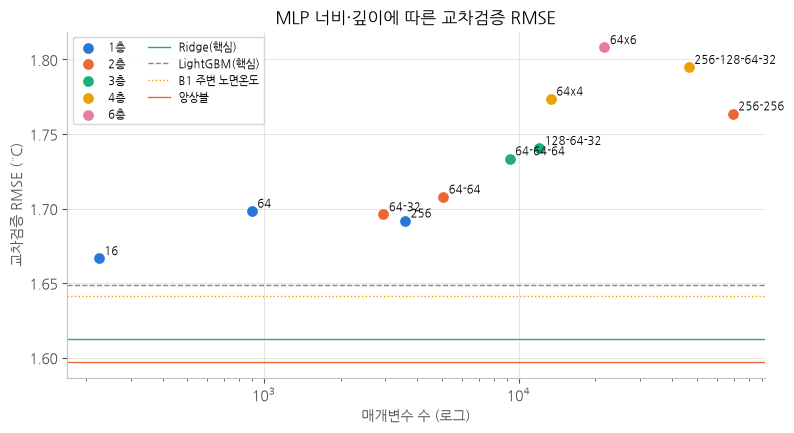

In [15]:
fig, ax = plt.subplots(figsize=(9, 4.5))
plain = mlp_table[~mlp_table.index.str.contains(",")]
for depth, g in plain.groupby("층 수"):
    ax.scatter(g["매개변수 수"], g["CV RMSE"], s=45, label=f"{depth}층", zorder=3)
    for name, r in g.iterrows():
        ax.annotate(name.split(" ")[1], (r["매개변수 수"], r["CV RMSE"]), fontsize=8, xytext=(4, 3),
                    textcoords="offset points")
for name, color, style in [("Ridge(핵심)", "#1baf7a", "-"), ("LightGBM(핵심)", "#898781", "--"),
                           ("B1 주변 노면온도", "#eda100", ":"), ("앙상블", "#eb6834", "-")]:
    ax.axhline(cmp_table.loc[name, "CV RMSE"], color=color, linestyle=style, linewidth=1, label=name)
ax.set_xscale("log")
ax.set_xlabel("매개변수 수 (로그)")
ax.set_ylabel("교차검증 RMSE (°C)")
ax.set_title("MLP 너비·깊이에 따른 교차검증 RMSE")
ax.legend(fontsize=8, ncol=2)
plt.show()

- **작을수록 좋고 깊을수록 나쁘다.** 1층 16개(매개변수 225개)가 1.667°C로 가장 좋고, 같은 너비 64에서 층을 늘리면
  1층 1.698 → 2층 1.708 → 3층 1.734 → 4층 1.774 → 6층 1.808°C로 꾸준히 나빠진다. 너비를 키워도(256-256: 1.764) 마찬가지이다.
- 규제를 강하게 하거나(L2 1: 1.679) 시드 5개를 평균하면(1.681) 조금 나아진다. 반대로 규제를 약하게 하면(L2 1e-5: 1.698) 나아지지 않는다.
  분산(과적합)을 줄이는 쪽이 도움이 되므로, MLP의 문제는 표현력 부족이 아니라 **지점 14곳에 대한 과적합**이다.
- 활성화 함수(tanh 1.710)나 목표 변수(B1 잔차 학습 1.671~1.776)를 바꿔도 개선되지 않는다.
- 가장 좋은 MLP도 Ridge(1.612)·LightGBM(1.649)보다 나쁘다. 신경망의 이점(복잡한 비선형 관계)을 쓰려면
  지금보다 훨씬 많은 관측 지점이 필요하다.

### 3-3. 앙상블 실험

여러 모델의 예측을 합치는 방식을 비교한다. 후보는 3-1의 12개 방법(B1, B2, Ridge, Ridge 상호작용, 스플라인 GAM, kNN, RF, Extra Trees,
MLP, LightGBM, LightGBM 선형트리, XGBoost)이다.

| 방식 | 내용 |
|------|------|
| 고정 조합 | 2절의 앙상블(LightGBM + Ridge + B1), 12개 전체 평균, 12개 중앙값 |
| 조합 선택 | 1~4개 조합(793가지) 중 단순 평균 RMSE가 가장 낮은 조합 |
| 낮·밤 조합 선택 | 낮과 밤에 다른 조합을 쓴다 |
| 가중 평균 | 비음수·합 1 가중치를 RMSE 최소가 되도록 최적화 |
| 전진 선택 (Caruana et al. 2004) | 중복을 허용해 RMSE를 가장 줄이는 모델을 25번 더한다 |

조합·가중치를 같은 교차검증 결과로 고르면 점수가 부풀려진다. 그래서 **중첩 교차검증**을 쓴다:
7묶음마다 나머지 12개 지점의 교차검증 예측만으로 조합·가중치를 고르고, 그 묶음 지점에 적용한다.

In [16]:
POOL = ["B1 주변 노면온도", "B2 기온+노면편차", "Ridge(핵심)", "Ridge 상호작용(2차)", "스플라인 GAM", "kNN(k=200)",
        "Random Forest", "Extra Trees", "MLP(64-32)", "LightGBM(핵심)", "LightGBM 선형트리", "XGBoost"]
P = oof[POOL].to_numpy()
y_tr = train_all[TARGET].to_numpy()
valid = ~np.isnan(y_tr) & ~np.isnan(P).any(axis=1)
stn_pos = {s: i for i, s in enumerate(sorted(train_all["stn"].unique()))}
stn_code = train_all["stn"].map(stn_pos).to_numpy()
is_night = ((hr >= 19) | (hr <= 6)).to_numpy()


def station_mse(pred, mask=valid):
    e2 = np.where(mask, (pred - y_tr) ** 2, 0)
    return np.bincount(stn_code, e2, len(stn_pos)) / np.bincount(stn_code, mask.astype(float), len(stn_pos))


def mean_rmse(mse, idx=None):
    r = np.sqrt(mse)
    return r.mean() if idx is None else r[idx].mean()


subsets = [c for k in range(1, 5) for c in itertools.combinations(range(len(POOL)), k)]
mse_all = np.array([station_mse(P[:, list(c)].mean(axis=1)) for c in subsets])
mse_night = np.array([station_mse(P[:, list(c)].mean(axis=1), valid & is_night) for c in subsets])
mse_day = np.array([station_mse(P[:, list(c)].mean(axis=1), valid & ~is_night) for c in subsets])
order = np.argsort(np.sqrt(mse_all).mean(axis=1))
print("조합 크기별 최저 RMSE (같은 교차검증으로 고름, 낙관적):",
      {k: round(min(mean_rmse(mse_all[j]) for j, c in enumerate(subsets) if len(c) == k), 4) for k in range(1, 5)})
pd.DataFrame([{"조합": " + ".join(POOL[i] for i in subsets[j]), "CV RMSE (낙관적)": mean_rmse(mse_all[j])}
              for j in order[:8]]).round(4)

조합 크기별 최저 RMSE (같은 교차검증으로 고름, 낙관적): {1: np.float64(1.6125), 2: np.float64(1.595), 3: np.float64(1.5816), 4: np.float64(1.5756)}


,조합,CV RMSE (낙관적)
0,B1 주변 노면온도 + Ridge(핵심) + kNN(k=200) + MLP(64-32),1.5756
1,B1 주변 노면온도 + Ridge(핵심) + Extra Trees + MLP(64-32),1.5804
2,B1 주변 노면온도 + 스플라인 GAM + kNN(k=200) + MLP(64-32),1.5809
3,B1 주변 노면온도 + kNN(k=200) + MLP(64-32),1.5816
4,B1 주변 노면온도 + kNN(k=200) + MLP(64-32) + LightGB...,1.5828
5,B1 주변 노면온도 + Ridge(핵심) + Ridge 상호작용(2차) + kNN(...,1.5829
6,B1 주변 노면온도 + Ridge(핵심) + kNN(k=200) + LightGBM...,1.5830
7,B1 주변 노면온도 + Ridge(핵심) + kNN(k=200),1.5830


In [17]:
def pick_subset(idx, max_size=4):
    j = min((j for j, c in enumerate(subsets) if len(c) <= max_size), key=lambda j: mean_rmse(mse_all[j], idx))
    w = np.zeros(len(POOL))
    w[list(subsets[j])] = 1 / len(subsets[j])
    return w


def pick_daynight(idx):
    jn = min(range(len(subsets)), key=lambda j: mean_rmse(mse_night[j], idx))
    jd = min(range(len(subsets)), key=lambda j: mean_rmse(mse_day[j], idx))
    wn, wd = np.zeros(len(POOL)), np.zeros(len(POOL))
    wn[list(subsets[jn])], wd[list(subsets[jd])] = 1 / len(subsets[jn]), 1 / len(subsets[jd])
    return wn, wd


def pick_simplex(idx):
    m = valid & np.isin(stn_code, idx)
    Pm, ym, sc = P[m], y_tr[m], stn_code[m]
    n_s = np.bincount(sc, minlength=len(stn_pos))[idx]

    def loss(w):
        w = np.abs(w) / np.abs(w).sum()
        return np.sqrt(np.bincount(sc, (Pm @ w - ym) ** 2, len(stn_pos))[idx] / n_s).mean()
    r = minimize(loss, np.full(len(POOL), 1 / len(POOL)), method="Powell", options={"maxiter": 3000, "xtol": 1e-3})
    return np.abs(r.x) / np.abs(r.x).sum()


def pick_greedy(idx, steps=25):
    chosen, cur = [], np.zeros(len(y_tr))
    for t in range(steps):
        b = min(range(len(POOL)), key=lambda i: mean_rmse(station_mse((cur * t + P[:, i]) / (t + 1)), idx))
        chosen.append(b)
        cur = (cur * t + P[:, b]) / (t + 1)
    return np.bincount(chosen, minlength=len(POOL)) / steps


def apply_w(w, X, night_mask):
    if isinstance(w, tuple):
        return np.where(night_mask, X @ w[0], X @ w[1])
    return X @ w


PICKERS = {"조합 선택 (≤ 4개)": pick_subset, "조합 선택 (≤ 2개)": lambda idx: pick_subset(idx, 2),
           "낮·밤 조합 선택": pick_daynight, "가중 평균 (비음수, 합 1)": pick_simplex, "전진 선택 (Caruana)": pick_greedy}
ens_pred = {"2절 앙상블 (LightGBM + Ridge + B1)": oof["앙상블"].to_numpy(), "12개 평균": P.mean(axis=1),
            "12개 중앙값": np.median(P, axis=1)}
picked = {}
for name, pick in PICKERS.items():
    pred = np.full(len(y_tr), np.nan)
    for val_stns in folds:
        idx = np.array([stn_pos[s] for s in stn_pos if s not in val_stns])
        rows = train_all["stn"].isin(val_stns).to_numpy()
        pred[rows] = apply_w(pick(idx), P[rows], is_night[rows])
    ens_pred[name] = pred
    picked[name] = pick(np.arange(len(stn_pos)))  # 14개 지점 전체로 고른 구성 (검증 지점용)

Ph = ho_cmp[POOL].to_numpy()
ho_night = ((holdout["time"].dt.hour >= 19) | (holdout["time"].dt.hour <= 6)).to_numpy()
ho_ens = {"2절 앙상블 (LightGBM + Ridge + B1)": ho_cmp["앙상블"].to_numpy(), "12개 평균": Ph.mean(axis=1),
          "12개 중앙값": np.median(Ph, axis=1)}
ho_ens.update({name: apply_w(w, Ph, ho_night) for name, w in picked.items()})
ens_table = pd.DataFrame({
    "CV RMSE (중첩, 정직)": {k: mean_rmse(station_mse(v)) for k, v in ens_pred.items()},
    "밤(19~06시)": {k: mean_rmse(station_mse(v, valid & is_night)) for k, v in ens_pred.items()},
    "검증 지점 RMSE (참고)": per_station_rmse(holdout, pd.DataFrame(ho_ens, index=holdout.index)).mean(),
})
print("14개 지점으로 고른 구성:")
for name, w in picked.items():
    ws = w if not isinstance(w, tuple) else w[0]
    print(f"  {name}:", {POOL[i]: round(x, 2) for i, x in enumerate(ws) if x > 0.01}, "(밤)" if isinstance(w, tuple) else "")
ens_table.round(4)

14개 지점으로 고른 구성:
  조합 선택 (≤ 4개): {'B1 주변 노면온도': np.float64(0.25), 'Ridge(핵심)': np.float64(0.25), 'kNN(k=200)': np.float64(0.25), 'MLP(64-32)': np.float64(0.25)} 
  조합 선택 (≤ 2개): {'B1 주변 노면온도': np.float64(0.5), 'kNN(k=200)': np.float64(0.5)} 
  낮·밤 조합 선택: {'B1 주변 노면온도': np.float64(0.33), 'Ridge(핵심)': np.float64(0.33), 'MLP(64-32)': np.float64(0.33)} (밤)
  가중 평균 (비음수, 합 1): {'B1 주변 노면온도': np.float64(0.32), 'Ridge(핵심)': np.float64(0.25), 'kNN(k=200)': np.float64(0.23), 'MLP(64-32)': np.float64(0.2)} 
  전진 선택 (Caruana): {'B1 주변 노면온도': np.float64(0.32), 'Ridge(핵심)': np.float64(0.24), 'kNN(k=200)': np.float64(0.24), 'MLP(64-32)': np.float64(0.2)} 


,"CV RMSE (중첩, 정직)",밤(19~06시),검증 지점 RMSE (참고)
2절 앙상블 (LightGBM + Ridge + B1),1.5969,1.0737,0.9381
12개 평균,1.5966,1.0720,0.9629
12개 중앙값,1.5966,1.0758,0.9671
조합 선택 (≤ 4개),1.5849,1.0482,0.9846
조합 선택 (≤ 2개),1.7012,1.1163,0.9845
낮·밤 조합 선택,1.6261,1.0666,0.9836
"가중 평균 (비음수, 합 1)",1.6249,1.0641,0.9722
전진 선택 (Caruana),1.6271,1.0665,0.9728


- 같은 교차검증으로 고른 최선 조합(B1 + Ridge + kNN + MLP, 1.576°C)은 낙관적이다. 중첩 교차검증의 정직한 점수는 1.585°C로,
  2절 앙상블(1.597)보다 0.012°C 낮다. 지점별 RMSE 차이의 표준오차(약 0.02°C)보다 작은 차이이다.
- 가중치를 학습하는 방식(가중 평균 1.625, 전진 선택 1.627, 낮·밤 분리 1.626)은 중첩 점수가 **단순 평균보다 나쁘다.**
  지점 12곳으로 가중치 12개를 정하면 가중치가 학습 지점에 맞춰지기 때문이다. 2개만 고르는 경우(1.701)는 묶음마다 고른 조합이 달라 더 나쁘다.
- 12개 전체 평균·중앙값(1.597)은 2절 앙상블과 같다. 같은 교차검증 예측으로 계산하면 B1 + Ridge 두 개의 평균이 이미 1.599°C이고,
  여기에 LightGBM을 더해도 1.597°C로 거의 같다. **앙상블의 이득은 "주변 관측 보간(B1)과 선형 모델(Ridge)을 단순 평균"하는 데서 대부분 나온다.**
- 검증 지점(참고)에서는 2절 앙상블(0.938)이 모든 대안(0.963~0.985)보다 낫다.
- **2절 앙상블을 유지한다.** 중첩 교차검증 이득(0.012°C)은 잡음 수준이고, 고른 조합에는 느리고 학습마다 결과가 달라지는 kNN·MLP가 들어가며,
  검증 지점에서는 오히려 나쁘다.

### 3-4. 잔차 구조: 무엇이 성능을 제한하는가

기법을 바꿔도 RMSE가 거의 그대로라면, 남은 오차가 모델로 배울 수 없는 성분일 가능성이 크다. Ridge 교차검증 잔차(추정 - 관측)의 분산을
나눠 본다.

- **지점 평균 편향**: 지점마다 늘 같은 방향으로 틀리는 양 (센서 위치·포장·주변 환경)
- **지점 x 시각 편향**: 지점마다 하루 중 같은 시각에 반복되는 오차 (예: 특정 지점이 매일 한낮에 덜 데워짐)
- 나머지: 날마다 달라지는 오차 (기상 보간 오차 등)

In [18]:
res = (oof["Ridge(핵심)"] - train_all[TARGET]).rename("r")
var_total = res.var()
var_station = res.groupby(train_all["stn"]).transform("mean").var()
var_station_hour = res.groupby([train_all["stn"], hr]).transform("mean").var()
pd.Series({"잔차 분산 (°C²)": var_total, "지점 평균 편향 비중": var_station / var_total,
           "지점 x 시각 편향 비중 (지점 평균 포함)": var_station_hour / var_total,
           "나머지 비중": 1 - var_station_hour / var_total}).round(3).to_frame("Ridge 교차검증 잔차")

,Ridge 교차검증 잔차
잔차 분산 (°C²),2.736
지점 평균 편향 비중,0.230
지점 x 시각 편향 비중 (지점 평균 포함),0.462
나머지 비중,0.538


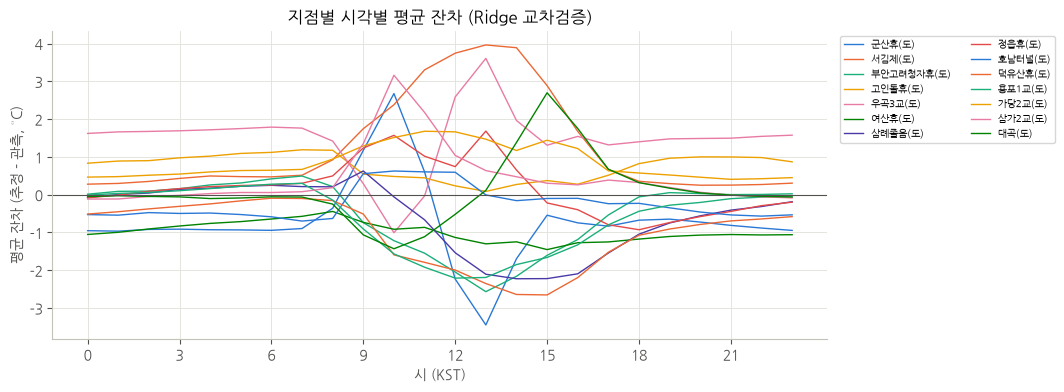

In [19]:
fig, ax = plt.subplots(figsize=(10, 4))
prof = res.groupby([train_all["stn"], hr]).mean().unstack(0)
for stn in prof.columns:
    ax.plot(prof.index, prof[stn], linewidth=1, label=stations.loc[stn, "name"])
ax.axhline(0, color="#52514e", linewidth=0.8)
ax.set_xticks(range(0, 24, 3))
ax.set_xlabel("시 (KST)")
ax.set_ylabel("평균 잔차 (추정 - 관측, °C)")
ax.set_title("지점별 시각별 평균 잔차 (Ridge 교차검증)")
ax.legend(ncol=2, fontsize=7, bbox_to_anchor=(1.01, 1), loc="upper left")
plt.show()

공간 보간(크리깅)으로 잔차를 줄일 수 있으려면 가까운 지점끼리 잔차가 **양의 상관**이어야 한다. 지점 쌍의 잔차 상관을 거리별로 본다.

In [20]:
pair_rows = []
for col, name in [("Ridge(핵심)", "Ridge"), ("B1 주변 노면온도", "B1")]:
    piv = (oof[col] - train_all[TARGET]).groupby([train_all["time"], train_all["stn"]]).first().unstack()
    corr = piv.corr()
    for a, b in itertools.combinations(piv.columns, 2):
        pair_rows.append({"잔차": name, "거리(km)": haversine_km(stations.loc[a], stations.loc[b]), "상관": corr.loc[a, b]})
pairs = pd.DataFrame(pair_rows)
pairs["거리대"] = pd.cut(pairs["거리(km)"], [0, 15, 30, 60, 200], labels=["15km 미만", "15~30km", "30~60km", "60km 이상"])
pairs.groupby(["거리대", "잔차"], observed=True)["상관"].agg(["mean", "count"]).unstack().round(2)

mean       count      
잔차         B1 Ridge    B1 Ridge
거리대                            
15km 미만 -0.58 -0.31     9     9
15~30km -0.08 -0.01    16    16
30~60km  0.01  0.12    25    25
60km 이상 -0.00  0.05    41    41

- 잔차 분산의 23%는 지점 평균 편향, 46%는 지점 x 시각 편향(평균 편향 포함)이다. **오차의 절반 가까이가 "그 지점이 매일 같은 시각에
  같은 방향으로 틀리는" 체계적 성분이다.** 그림처럼 지점 간 편향은 한낮(11~16시)에 ±2~4°C로 커진다. 일사로 데워지는 정도가 지점마다 다르기 때문이다.
- 이 성분은 센서 위치, 포장, 주변 차폐, 교량 구조 같은 지점 고유 특성에서 나온다. 입력 변수에 이를 설명하는 정보가 없고 학습 지점이 14곳뿐이라
  어떤 기법으로도 배울 수 없다. 3-1·3-2에서 기법을 바꿔도 RMSE가 거의 같은 이유이다.
- 15km 미만 지점 쌍의 잔차 상관은 **음수**이다 (Ridge -0.31, B1 -0.58). `nbr_rst`가 이미 이웃 관측값을 쓰기 때문이다.
  이웃 B가 늘 따뜻한 지점이면 A의 추정은 B 때문에 너무 높아지고, B의 추정(A의 관측을 씀)은 너무 낮아진다.
  그래서 잔차를 다시 공간 보간하면 같은 정보를 두 번 쓰는 셈이 되어 3-1의 "Ridge + 잔차 IDW"가 크게 나빠졌다.
  30km 이상 떨어지면 상관이 거의 0이다. 이 관측망 밀도에서는 크리깅·가우스 과정 같은 공간 통계로 잔차를 줄일 여지가 없다.

### 3-5. 지점 특성 변수 실험

3-4의 지점 고유 편향을 지점 특성으로 설명할 수 있는지 본다. 후보 지점 특성:

| 변수 | 의미 |
|------|------|
| `elev`, `tpi`, `relief` | 표고, 주변(1km) 대비 상대 높이, 기복량 |
| `shade_winter` | 동지 무렵 지형에 가려지는 직달 일사 비율 |
| `dist_river`, `log_bridge`, `log_tunnel` | 하천·교량·터널까지 거리 (교량·터널은 log10) |
| `bridge` | 교량 위(50m 이내) 여부 |
| `dz_nbr` | 주변 RWIS 3곳(IDW) 대비 높이 차. `nbr_rst`의 고정 감률 보정이 밤 역전층에서 틀릴 수 있는 정도 |
| `rest_area` | 센서가 휴게소·졸음쉼터 안에 있는지 (지점명 기준). 학습 지점 14곳 중 7곳 |

먼저 지점별 평균 잔차(편향)와 지점 특성의 순위 상관을 상황별로 본다 (지점 14곳).

In [21]:
import geopandas as gpd
from scipy.spatial.distance import cdist
from scipy.stats import spearmanr

site = stations.copy()
_g = gpd.GeoSeries(gpd.points_from_xy(site["lon"], site["lat"]), crs=4326).to_crs(5179)
_xy = np.c_[_g.x, _g.y]
_src = np.flatnonzero(~site["holdout"].to_numpy())
_d = cdist(_xy, _xy[_src])
for i, j in enumerate(_src):
    _d[j, i] = np.inf  # 학습 지점은 자기 자신 제외 (02-2의 주변 RWIS 변수와 같은 방식)
_near = np.argsort(_d, axis=1)[:, :3]
_w = 1 / np.maximum(np.take_along_axis(_d, _near, 1), 50) ** 2
site["dz_nbr"] = site["elev"] - (_w * site["elev"].to_numpy()[_src][_near]).sum(1) / _w.sum(1)
site["log_bridge"] = np.log10(site["dist_bridge"] + 10)
site["log_tunnel"] = np.log10(site["dist_tunnel"] + 10)
site["bridge"] = (site["dist_bridge"] < 50).astype(float)
site["rest_area"] = site["name"].str.contains("휴|졸음").astype(float)
SITE = ["elev", "tpi", "relief", "shade_winter", "dist_river", "log_bridge", "log_tunnel", "bridge", "dz_nbr", "rest_area"]

night_all = train_all["sun_elev"] <= 0
rci = night_all * (1 - train_all["cloud"].clip(0, 10) / 10) * (1 - train_all["ws"] / 5).clip(0, 1)  # 복사냉각 지수
SITUATIONS = {"전체": np.ones(len(train_all), bool), "밤": ((hr >= 19) | (hr <= 6)).to_numpy(),
              "맑고 고요한 밤": (rci > 0.5).to_numpy(), "한낮(11~14시)": ((hr >= 11) & (hr <= 14)).to_numpy()}
bias = pd.DataFrame({k: res[m].groupby(train_all.loc[m, "stn"]).mean() for k, m in SITUATIONS.items()})
site_corr = pd.DataFrame({k: {c: spearmanr(bias[k], site.loc[bias.index, c])[0] for c in SITE} for k in SITUATIONS})
site_corr.round(2)

,전체,밤,맑고 고요한 밤,한낮(11~14시)
elev,-0.28,-0.21,-0.26,-0.22
tpi,-0.03,0.08,0.28,-0.10
relief,-0.12,-0.13,-0.26,-0.08
shade_winter,-0.24,-0.38,-0.51,-0.12
dist_river,0.21,0.04,-0.08,0.20
log_bridge,-0.38,-0.29,-0.26,-0.46
log_tunnel,-0.16,0.02,0.17,-0.16
bridge,0.37,0.15,0.11,0.41
dz_nbr,-0.22,-0.44,-0.43,-0.03
rest_area,-0.55,-0.41,-0.19,-0.55


상관이 있어 보이는 특성을 모델에 넣는 방법은 두 가지이다.

1. **행 단위**: 지점 특성을 그대로 입력 변수에 더한다 (10분 단위 40만 행).
2. **지점 단위 2단계 보정**: 기본 모델(Ridge)의 잔차로 지점 x 시각별 편향을 재고, 그 편향을 지점 특성으로 회귀(표본 12개 지점, 릿지 규제 λ)해
   새 지점의 편향을 예측해 뺀다. 학습 지점의 잔차는 **내부 교차검증**으로 구해 낙관적인 잔차를 쓰지 않는다.

In [22]:
STATIC_ROW = ["elev", "tpi", "relief", "shade_winter", "dist_river", "dist_bridge", "dist_tunnel"]
row_exp = {}
for name, make in [("Ridge", make_ridge), ("LightGBM", lambda: lgb.LGBMRegressor(**dict(
        LGB_PARAMS["LightGBM(핵심)"], n_estimators=best_iter["LightGBM(핵심)"])))]:
    pred = pd.Series(np.nan, index=train_all.index)
    for val_stns in folds:
        rows = train_all["stn"].isin(val_stns)
        tr = train_all[~rows].dropna(subset=[TARGET])
        pred[rows] = make().fit(tr[CORE + STATIC_ROW], tr[TARGET]).predict(train_all.loc[rows, CORE + STATIC_ROW])
    base_name = "Ridge(핵심)" if name == "Ridge" else "LightGBM(핵심)"
    r = per_station_rmse(train_all, pd.DataFrame({"x": pred}))["x"]
    row_exp[f"{name} + 정적 변수 7개 (행 단위)"] = {"CV RMSE": r.mean(), "핵심 변수만": st_rmse[base_name].mean(),
                                               "나빠진 지점 수": int((r > st_rmse[base_name]).sum())}
pd.DataFrame(row_exp).T.round(3)

,CV RMSE,핵심 변수만,나빠진 지점 수
Ridge + 정적 변수 7개 (행 단위),1.914,1.612,10.0
LightGBM + 정적 변수 7개 (행 단위),1.893,1.649,10.0


In [23]:
# 바깥 묶음마다 학습 지점(12곳)의 내부 교차검증 잔차
inner_res = {}
for k, val_stns in enumerate(folds):
    tr = train_all[~train_all["stn"].isin(val_stns)]
    r = pd.Series(np.nan, index=tr.index)
    for j, f in enumerate(folds):
        if j == k:
            continue
        ir = tr["stn"].isin(f)
        src = tr[~ir].dropna(subset=[TARGET])
        r[ir] = make_ridge().fit(src[CORE], src[TARGET]).predict(tr.loc[ir, CORE]) - tr.loc[ir, TARGET]
    inner_res[k] = r

SOLAR_MAX = train_all["solar_eff"].max()


def regime_of(df, reg_name):
    """시각 24구분 또는 상황 4구분(맑고 고요한 밤 / 그 밖의 밤 / 햇빛 강한 낮 / 그 밖의 낮)."""
    if reg_name == "시각 24구분":
        return df["time"].dt.hour.to_numpy()
    night = df["sun_elev"] <= 0
    calm_clear = night * (1 - df["cloud"].clip(0, 10) / 10) * (1 - df["ws"] / 5).clip(0, 1) > 0.5
    return np.select([calm_clear.to_numpy(), night.to_numpy(), (df["solar_eff"] > 0.25 * SOLAR_MAX).to_numpy()],
                     [0, 1, 2], 3)


REGIMES = {name: (regime_of(train_all, name), n) for name, n in [("시각 24구분", 24), ("상황 4구분", 4)]}


def fit_bias(stn_ids, resid, regime, n_reg, desc, lam):
    """지점 x 상황 평균 잔차를 지점 특성 desc로 회귀(릿지 λ). 반환: 대상 지점 목록 -> (지점 x 상황) 편향 배열."""
    b = pd.DataFrame({"s": stn_ids, "g": regime, "r": resid}).dropna().groupby(["s", "g"])["r"].mean().unstack()
    b = b.reindex(columns=range(n_reg))
    X = site.loc[b.index, list(desc)].to_numpy(float)
    mu, sd = X.mean(0), X.std(0) + 1e-9
    coefs = []
    for gi in range(n_reg):
        yb = b[gi].to_numpy()
        ok = ~np.isnan(yb)
        A = np.c_[np.ones(ok.sum()), ((X - mu) / sd)[ok]]
        coefs.append(np.linalg.solve(A.T @ A + lam * np.diag([0.0] + [1.0] * len(desc)), A.T @ yb[ok]))
    coefs = np.array(coefs)
    return lambda tgt: coefs[:, 0][None, :] + ((site.loc[tgt, list(desc)].to_numpy(float) - mu) / sd) @ coefs[:, 1:].T


def corrected_oof(desc, reg_name, lam, base=oof["Ridge(핵심)"].to_numpy()):
    regime, n_reg = REGIMES[reg_name]
    pred = base.copy()
    for k, val_stns in enumerate(folds):
        rows = train_all["stn"].isin(val_stns).to_numpy()
        f = fit_bias(train_all.loc[~rows, "stn"].to_numpy(), inner_res[k].to_numpy(), regime[~rows], n_reg, desc, lam)
        B = f(list(val_stns))
        pos = {s: i for i, s in enumerate(val_stns)}
        pred[rows] -= B[train_all.loc[rows, "stn"].map(pos).to_numpy(), regime[rows]]
    return pred


CONFIGS = [((), r, 0.0) for r in REGIMES] + [((c,), r, lam) for c in SITE for r in REGIMES for lam in (0.0, 1.0, 5.0)]
two_rows = []
for desc, reg_name, lam in CONFIGS:
    r = per_station_rmse(train_all, pd.DataFrame({"x": corrected_oof(desc, reg_name, lam)}))["x"]
    two_rows.append({"지점 특성": "+".join(desc) or "(없음: 상황별 평균 편향)", "상황 구분": reg_name, "λ": lam,
                     "CV RMSE": r.mean(), "Ridge 대비": r.mean() - st_rmse["Ridge(핵심)"].mean(),
                     "개선 지점 수": int((r < st_rmse["Ridge(핵심)"]).sum())})
two_table = pd.DataFrame(two_rows).sort_values("CV RMSE")
two_table.head(10).round(4)

,지점 특성,상황 구분,λ,CV RMSE,Ridge 대비,개선 지점 수
58,rest_area,시각 24구분,5.0,1.5717,-0.0408,9
57,rest_area,시각 24구분,1.0,1.5810,-0.0314,9
61,rest_area,상황 4구분,5.0,1.5842,-0.0282,9
56,rest_area,시각 24구분,0.0,1.5867,-0.0258,9
60,rest_area,상황 4구분,1.0,1.5925,-0.0200,9
59,rest_area,상황 4구분,0.0,1.5972,-0.0153,9
49,bridge,상황 4구분,5.0,1.5975,-0.0150,9
37,log_bridge,상황 4구분,5.0,1.6043,-0.0082,9
46,bridge,시각 24구분,5.0,1.6072,-0.0052,8
1,(없음: 상황별 평균 편향),상황 4구분,0.0,1.6083,-0.0041,8


위 표는 60여 가지 설정 가운데 가장 좋은 것을 같은 교차검증으로 고른 것이라 낙관적이다. 두 가지로 확인한다.

1. **중첩 선택**: 바깥 묶음마다 학습 지점 12곳의 내부 교차검증만으로 설정을 고르고 묶음 지점에 적용한다.
2. **검증 지점**: 14개 지점의 교차검증 잔차로 보정식을 학습해 2절 앙상블의 검증 지점 예측에 적용한다 (검증 지점 3곳은 모두 휴게소가 아니다).

In [24]:
nested_pred, nested_pick = oof["Ridge(핵심)"].to_numpy().copy(), []
for k, val_stns in enumerate(folds):
    rows = train_all["stn"].isin(val_stns).to_numpy()
    tr_stn, r_k = train_all.loc[~rows, "stn"].to_numpy(), inner_res[k].to_numpy()
    inner_folds = [f for j, f in enumerate(folds) if j != k]
    best, best_score = None, np.inf
    for desc, reg_name, lam in CONFIGS:
        regime, n_reg = REGIMES[reg_name]
        reg_k = regime[~rows]
        corr = r_k.copy()
        for f in inner_folds:
            ir = np.isin(tr_stn, f)
            B = fit_bias(tr_stn[~ir], r_k[~ir], reg_k[~ir], n_reg, desc, lam)(list(f))
            pos = {s: i for i, s in enumerate(f)}
            corr[ir] = r_k[ir] - B[[pos[s] for s in tr_stn[ir]], reg_k[ir]]
        score = np.sqrt(pd.Series(corr ** 2).groupby(tr_stn).mean()).mean()
        if score < best_score:
            best, best_score = (desc, reg_name, lam), score
    desc, reg_name, lam = best
    regime, n_reg = REGIMES[reg_name]
    B = fit_bias(tr_stn, r_k, regime[~rows], n_reg, desc, lam)(list(val_stns))
    pos = {s: i for i, s in enumerate(val_stns)}
    nested_pred[rows] -= B[train_all.loc[rows, "stn"].map(pos).to_numpy(), regime[rows]]
    nested_pick.append(f"{'+'.join(desc) or '없음'} / {reg_name} / λ={lam}")
r_nested = per_station_rmse(train_all, pd.DataFrame({"x": nested_pred}))["x"]
print(f"중첩 선택 CV RMSE {r_nested.mean():.4f} (Ridge {st_rmse['Ridge(핵심)'].mean():.4f}), "
      f"개선 지점 {int((r_nested < st_rmse['Ridge(핵심)']).sum())}/14")
print("묶음별 선택:", pd.Series(nested_pick).value_counts().to_dict())

중첩 선택 CV RMSE 1.6777 (Ridge 1.6125), 개선 지점 6/14
묶음별 선택: {'rest_area / 시각 24구분 / λ=5.0': 3, 'rest_area / 시각 24구분 / λ=1.0': 2, 'tpi / 상황 4구분 / λ=0.0': 1, 'bridge / 시각 24구분 / λ=5.0': 1}


In [25]:
best_desc, best_reg, best_lam = two_table.iloc[0][["지점 특성", "상황 구분", "λ"]]
best_desc = () if best_desc.startswith("(없음") else tuple(best_desc.split("+"))
reg_tr, n_best = REGIMES[best_reg]
reg_ho = regime_of(holdout, best_reg)
rows_ho = []
for base_name, base_oof, base_ho in [("Ridge(핵심)", oof["Ridge(핵심)"], ho_cmp["Ridge(핵심)"]),
                                     ("2절 앙상블", oof["앙상블"], ho_cmp["앙상블"])]:
    f = fit_bias(train_all["stn"].to_numpy(), (base_oof - train_all[TARGET]).to_numpy(), reg_tr, n_best, best_desc,
                 best_lam)
    B = f(list(config.HOLDOUT_STATIONS))
    pos = {s: i for i, s in enumerate(config.HOLDOUT_STATIONS)}
    corrected = base_ho.to_numpy() - B[holdout["stn"].map(pos).to_numpy(), reg_ho]
    before = per_station_rmse(holdout, pd.DataFrame({"x": base_ho}))["x"]
    after = per_station_rmse(holdout, pd.DataFrame({"x": corrected}, index=holdout.index))["x"]
    rows_ho.append({"기본 모델": base_name, "보정 전 검증 RMSE": before.mean(), "보정 후 검증 RMSE": after.mean(),
                    "보정 전 BIAS": (base_ho - holdout[TARGET]).mean(), "보정 후 BIAS": (corrected - holdout[TARGET]).mean()})
print(f"검증 지점에 적용한 설정: {'+'.join(best_desc) or '없음'} / {best_reg} / λ={best_lam}")
pd.DataFrame(rows_ho).set_index("기본 모델").round(3)

검증 지점에 적용한 설정: rest_area / 시각 24구분 / λ=5.0


,보정 전 검증 RMSE,보정 후 검증 RMSE,보정 전 BIAS,보정 후 BIAS
기본 모델,,,,
Ridge(핵심),0.994,1.185,-0.410,-0.761
2절 앙상블,0.938,1.109,-0.385,-0.670


- **진단**: 지점 편향과 상관이 가장 큰 특성은 다음과 같다.
  - 휴게소 여부 (전체·한낮 ρ = -0.55): 휴게소 센서는 모델보다 따뜻하게 관측된다.
  - 교량 거리 (한낮 -0.46): 교량에 가까울수록 한낮에 모델보다 차갑다. 01-7의 13-7과 같은 방향이다.
  - 주변 대비 높이 차 (밤 -0.44): 주변보다 높은 지점은 밤에 모델보다 따뜻하다. 역전층 때문이다.
  - 겨울 그늘 (맑고 고요한 밤 -0.51)

  다만 지점 14곳의 순위 상관은 |ρ| ≥ 0.54여야 5% 수준에서 유의하다.
- **행 단위**로 정적 변수를 넣으면 Ridge·LightGBM 모두 크게 나빠진다 (1.914, 1.893°C, 14곳 중 10곳 악화).
  40만 행 기준의 규제는 지점 수준에서는 사실상 없는 것과 같아, 정적 변수가 지점 식별자가 된다.
- **지점 단위 2단계 보정**은 겉보기에는 효과가 있다. 휴게소 여부로 시각별 편향을 보정하면 1.612 → 1.572°C로 줄어든다 (14곳 중 9곳 개선).
  학습 자료에서 휴게소 센서는 한낮에 모델보다 약 2°C 따뜻하게 관측된다. 휴게소 진입로·주차장 안의 센서는 본선보다 바람이 막히고
  차량 통행이 적어 더 데워질 가능성이 있다.
- 그러나 설정을 고르는 과정까지 포함한 **중첩 선택에서는 1.678°C로 오히려 나빠진다.** 묶음마다 고르는 특성이 바뀐다.
  **검증 지점에 적용해도 0.938 → 1.109°C로 나빠진다.** 검증 지점 3곳은 모두 휴게소가 아니다. 그런데 학습 자료의 비휴게소 지점
  (서김제·우곡3교처럼 한낮에 모델보다 차가운 곳)과 달리 오히려 모델보다 따뜻했다 (BIAS -0.39°C).
  비휴게소 지점끼리도 편차가 커서 "휴게소 여부" 하나로 설명되지 않는다.
- **결론: 지점 특성의 효과는 지점 14곳으로는 안정적으로 추정되지 않으므로 최종 모델에 넣지 않는다.**
  학습 지점의 절반이 휴게소 안 센서라는 점은 본선 구간 추정에 남아 있을 수 있는 편향 요인으로 05-1의 해석에 적는다.

### 3-6. 정리

| 실험 | 결과 (교차검증 RMSE, °C) | 판단 |
|------|------------------------|------|
| 다른 고전 기법 12종 (3-1) | 단일 기법 1.612~1.755. Ridge가 가장 낮고 LightGBM(1.649)은 학습 없는 B1(1.642)과 같은 수준 | LightGBM이 최선이 아니다. 상위권 차이는 잡음 수준이다 |
| MLP 구조 20가지 (3-2) | 작을수록 좋다 (1층 16: 1.667, 6층: 1.808) | 지점 14곳으로는 신경망의 용량을 쓸 수 없다 |
| 앙상블 8가지 (3-3) | 중첩 정직 점수 1.585~1.701. 단순 평균 1.597, 가중치 학습 1.625 | 단순 평균(2절 앙상블)을 유지한다 |
| 잔차 공간 보간 (3-4) | 2.223 | 이웃 잔차가 음의 상관이라 쓸 수 없다 |
| 지점 특성 (3-5) | 겉보기 1.572 → 중첩 1.678, 검증 지점 0.938 → 1.109 | 넣지 않는다 |

- **최종 방법은 2절 그대로 앙상블(LightGBM(핵심) + Ridge(핵심) + B1)이다.** 앙상블 이득의 대부분은 B1과 Ridge의 평균에서 나온다.
  LightGBM은 "가장 좋은 모델"이라서가 아니라, 선형 모델과 오차 양상이 다른 비선형 모델로 다양성을 조금 더하는 역할이다.
- **성능을 제한하는 것은 모델 형태가 아니라 지점 고유 편향(잔차의 46%)과 학습 지점 수(14곳)이다.**
  더 나아지려면 센서 설치 위치·포장·교량 구조 같은 지점 정보나 더 많은 관측 지점이 필요하다.

## 저장

- `data/results/estimation_model_comparison.csv`, `estimation_mlp_architectures.csv`, `estimation_ensembles.csv`,
  `estimation_site_correction.csv`: 3절의 기법 비교·MLP 구조·앙상블·지점 특성 보정 실험 결과

In [ ]:
cmp_table.round(4).to_csv(config.RESULT_DIR / "estimation_model_comparison.csv", encoding="utf-8-sig")
mlp_table.round(4).to_csv(config.RESULT_DIR / "estimation_mlp_architectures.csv", encoding="utf-8-sig")
ens_table.round(4).to_csv(config.RESULT_DIR / "estimation_ensembles.csv", encoding="utf-8-sig")
two_table.round(4).to_csv(config.RESULT_DIR / "estimation_site_correction.csv", index=False, encoding="utf-8-sig")
print("저장 완료")